In [13]:
!pip install -q python-igraph leidenalg

##Import Library

In [43]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import igraph as ig
import leidenalg as la
import leidenalg
from collections import Counter
from sklearn.metrics import adjusted_rand_score

##Menentukan Path Dataset

In [15]:
DATA_DIR = "/content/"

edges_path = os.path.join(DATA_DIR, "musae_git_edges.csv")
target_path = os.path.join(DATA_DIR, "musae_git_target.csv")
features_path = os.path.join(DATA_DIR, "musae_git_features.json")

print("Dataset tersedia:", os.path.exists(edges_path),
      os.path.exists(target_path),
      os.path.exists(features_path))

Dataset tersedia: True True True


In [34]:
edges = pd.read_csv(edges_path)
target = pd.read_csv(target_path)

with open(features_path, 'r') as file:
    features = json.load(file)



##Melihat Struktur Dataset:

In [23]:
print("Edges:", edges.shape)
display(edges.head())

print("Target:", target.shape)
display(target.head())

print("Features:", len(features))

Edges: (289003, 2)


,id_1,id_2
0,0,23977
1,1,34526
2,1,2370
3,1,14683
4,1,29982


Target: (37700, 3)


,id,name,ml_target
0,0,Eiryyy,0
1,1,shawflying,0
2,2,JpMCarrilho,1
3,3,SuhwanCha,0
4,4,sunilangadi2,1


Features: 37700


##Membuat Graph

In [24]:
G = nx.from_pandas_edgelist(
    edges,
    source='id_1',
    target='id_2'
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 37700
Edges: 289003


##Degree Distribution

In [25]:
degree_values = [d for _, d in G.degree()]

print("Rata-rata Degree:", np.mean(degree_values))
print("Degree Tertinggi:", max(degree_values))
print("Degree Terendah:", min(degree_values))

Rata-rata Degree: 15.331724137931035
Degree Tertinggi: 9458
Degree Terendah: 1


##Visualisasi Degree Distribution

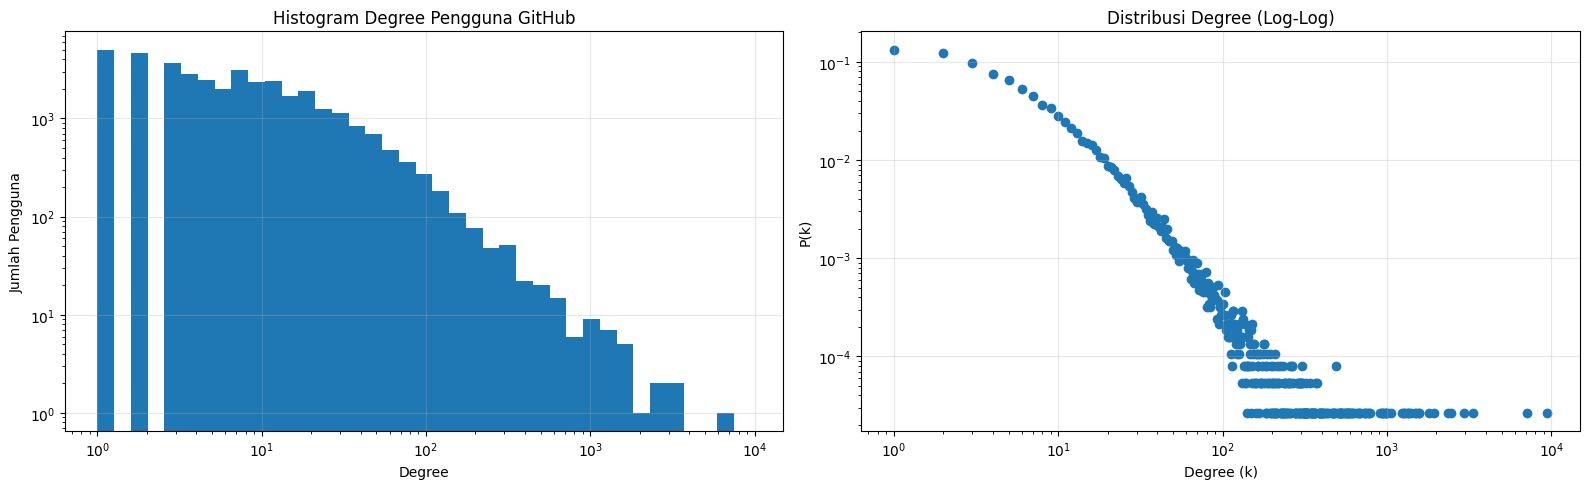

In [49]:
degree_array = np.array(degree_values)

degree_unique, degree_counts = np.unique(
    degree_array,
    return_counts=True
)

degree_probability = degree_counts / len(degree_array)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histogram Degree
axes[0].hist(
    degree_array,
    bins=np.logspace(
        np.log10(1),
        np.log10(degree_array.max()),
        40
    )
)

axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_title('Histogram Degree Pengguna GitHub')
axes[0].set_xlabel('Degree')
axes[0].set_ylabel('Jumlah Pengguna')
axes[0].grid(alpha=0.3)

# Distribusi Degree Log-Log
axes[1].scatter(degree_unique, degree_probability)

axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Distribusi Degree (Log-Log)')
axes[1].set_xlabel('Degree (k)')
axes[1].set_ylabel('P(k)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

##Connected Components

In [30]:
components = list(nx.connected_components(G))

component_sizes = [len(c) for c in components]

print("Jumlah Components:", len(components))
print("Komponen Terbesar:", max(component_sizes))
print("Komponen Terkecil:", min(component_sizes))

Jumlah Components: 1
Komponen Terbesar: 37700
Komponen Terkecil: 37700


##Konversi NetworkX ke igraph

In [39]:
target = target.sort_values("id").reset_index(drop=True)

assert (target["id"].values == np.arange(len(target))).all()

g = ig.Graph(
    n=len(target),
    edges=list(zip(edges["id_1"], edges["id_2"])),
    directed=False
)

labels = target["ml_target"].values

print("Simpul:", g.vcount())
print("Sisi:", g.ecount())
print("Simple:", g.is_simple())
print("Connected:", g.is_connected())
print("Density:", round(g.density(), 6))

Simpul: 37700
Sisi: 289003
Simple: True
Connected: True
Density: 0.000407


##Louvain Community Detection

In [40]:
louvain = g.community_multilevel(resolution=1.0)

louvain_membership = louvain.membership

print("Jumlah Komunitas:", len(louvain))
print("Modularity:", round(louvain.modularity, 6))

Jumlah Komunitas: 100
Modularity: 0.452879


##Leiden Community Detection.

In [44]:
leiden = leidenalg.find_partition(
    g,
    leidenalg.RBConfigurationVertexPartition,
    resolution_parameter=1.0
)

leiden_membership = leiden.membership
leiden_modularity = g.modularity(leiden_membership)

print("Jumlah Komunitas:", len(leiden))
print("Modularity:", round(leiden_modularity, 6))

Jumlah Komunitas: 31
Modularity: 0.454399


##Eksperimen Resolution Gamma

In [45]:
gamma_values = [0.5, 1.0, 1.5, 2.0]

gamma_results = []

for gamma in gamma_values:
    partition = leidenalg.find_partition(
        g,
        leidenalg.RBConfigurationVertexPartition,
        resolution_parameter=gamma
    )

    modularity = g.modularity(partition.membership)

    gamma_results.append({
        "Gamma": gamma,
        "Jumlah Komunitas": len(partition),
        "Modularity": modularity
    })

gamma_df = pd.DataFrame(gamma_results)
gamma_df

,Gamma,Jumlah Komunitas,Modularity
0,0.5,17,0.365990
1,1.0,30,0.453682
2,1.5,35,0.445740
3,2.0,45,0.414895


##Eksperimen Random Seed

In [46]:
seeds = [0, 1, 2, 3, 4]

seed_results = []

for seed in seeds:
    partition = leidenalg.find_partition(
        g,
        leidenalg.RBConfigurationVertexPartition,
        resolution_parameter=1.0,
        seed=seed
    )

    modularity = g.modularity(partition.membership)

    seed_results.append({
        "Seed": seed,
        "Jumlah Komunitas": len(partition),
        "Modularity": modularity
    })

seed_df = pd.DataFrame(seed_results)
seed_df

,Seed,Jumlah Komunitas,Modularity
0,0,86,0.458497
1,1,36,0.454610
2,2,26,0.456152
3,3,32,0.458396
4,4,33,0.452544


##Bagian 2

##1 Bagaimana perbedaan hasil Louvain dan Leiden berdasarkan modularity, ukuran komunitas, keterhubungan internal, dan waktu komputasi?

In [50]:
import time
import random

comparison_results = []

# Louvain
random.seed(0)
start = time.perf_counter()

louvain_test = g.community_multilevel(resolution=1.0)

louvain_time = time.perf_counter() - start

# Leiden
start = time.perf_counter()

leiden_test = leidenalg.find_partition(
    g,
    leidenalg.RBConfigurationVertexPartition,
    resolution_parameter=1.0,
    seed=0
)

leiden_time = time.perf_counter() - start

# Analisis kedua algoritma
for name, partition, runtime in [
    ("Louvain", louvain_test, louvain_time),
    ("Leiden", leiden_test, leiden_time)
]:
    membership = partition.membership
    sizes = partition.sizes()

    disconnected = 0

    for community_id in range(len(partition)):
        vertices = [
            i for i, c in enumerate(membership)
            if c == community_id
        ]

        subgraph = g.induced_subgraph(vertices)

        if len(subgraph.connected_components()) > 1:
            disconnected += 1

    comparison_results.append({
        "Algoritma": name,
        "Jumlah Komunitas": len(partition),
        "Modularity": g.modularity(membership),
        "Ukuran Minimum": min(sizes),
        "Ukuran Median": np.median(sizes),
        "Ukuran Maksimum": max(sizes),
        "Komunitas Terpecah": disconnected,
        "Waktu (detik)": runtime
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df.round(4)

,Algoritma,Jumlah Komunitas,Modularity,Ukuran Minimum,Ukuran Median,Ukuran Maksimum,Komunitas Terpecah,Waktu (detik)
0,Louvain,35,0.4446,3,6.0,7753,3,0.9512
1,Leiden,86,0.4585,2,2.0,10067,0,6.5658




Berdasarkan hasil perbandingan, Leiden menghasilkan nilai modularity lebih tinggi dibandingkan Louvain, yaitu 0.4585 berbanding 0.4446. Leiden juga menghasilkan lebih banyak komunitas, yaitu 86 komunitas, sedangkan Louvain menghasilkan 35 komunitas.

Dari sisi ukuran komunitas, Louvain memiliki ukuran median 6 anggota, sedangkan Leiden 2 anggota. Pada keterhubungan internal, Louvain memiliki 3 komunitas yang terpecah, sementara Leiden tidak memiliki komunitas yang terpecah. Namun, waktu komputasi Leiden lebih lama, yaitu sekitar 6.57 detik dibandingkan Louvain yang hanya sekitar 0.95 detik.

Dengan demikian, Leiden memberikan modularity dan keterhubungan internal yang lebih baik pada percobaan ini, tetapi membutuhkan waktu komputasi lebih lama.

##2 Seberapa besar parameter resolusi dan random seed memengaruhi struktur serta kestabilan komunitas?

In [51]:
# Ringkasan eksperimen gamma
gamma_summary = gamma_df[
    ["Jumlah Komunitas", "Modularity"]
].agg(["min", "max", "std"])

# Ringkasan eksperimen random seed
seed_summary = seed_df[
    ["Jumlah Komunitas", "Modularity"]
].agg(["min", "max", "std"])

print("Pengaruh Resolution Gamma:")
display(gamma_summary.round(4))

print("Pengaruh Random Seed:")
display(seed_summary.round(4))

Pengaruh Resolution Gamma:


,Jumlah Komunitas,Modularity
min,17.000,0.3660
max,45.000,0.4537
std,11.644,0.0397


Pengaruh Random Seed:


,Jumlah Komunitas,Modularity
min,26.0000,0.4525
max,86.0000,0.4585
std,24.5316,0.0025




Nilai gamma memengaruhi jumlah komunitas yang terbentuk, yaitu antara 17 hingga 45 komunitas. Perbedaan random seed menghasilkan variasi yang lebih besar, mulai dari 26 hingga 86 komunitas. Meskipun begitu, nilai modularity tetap relatif stabil dengan standar deviasi 0.0025.

##3 Bagaimana hubungan antara komunitas yang ditemukan dengan kategori pengembang Web dan Machine Learning?

In [52]:
community_data = pd.DataFrame({
    "Komunitas": leiden_membership,
    "Kategori": labels
})

community_table = pd.crosstab(
    community_data["Komunitas"],
    community_data["Kategori"]
)

community_table

Kategori,0,1
Komunitas,,
0,8158,416
1,2224,5721
2,5522,1332
3,4507,873
4,2668,145
5,2154,475
6,1234,352
7,439,99
8,364,157


In [53]:
community_percentage = community_table.div(
    community_table.sum(axis=1),
    axis=0
) * 100

community_percentage.round(2)

Kategori,0,1
Komunitas,,
0,95.15,4.85
1,27.99,72.01
2,80.57,19.43
3,83.77,16.23
4,94.85,5.15
5,81.93,18.07
6,77.81,22.19
7,81.60,18.40
8,69.87,30.13




Komposisi kategori pengembang berbeda pada setiap komunitas. Sebagian besar komunitas didominasi kategori 0, sedangkan beberapa komunitas seperti komunitas 1 dan 13 lebih banyak berisi kategori 1. Hal ini menunjukkan bahwa komunitas yang terbentuk tidak selalu memiliki kategori pengembang yang sama

Komunitas 0, 2, dan 3 didominasi oleh Web Developer, sedangkan komunitas 1 dan 13 didominasi oleh Machine Learning Developer. Hal ini menunjukkan bahwa beberapa komunitas memiliki kecenderungan bidang keahlian yang sama, meskipun terdapat juga komunitas yang anggotanya berasal dari kedua bidang tersebut.

## 4 Pengguna mana yang berpotensi menjadi penghubung antarkomunitas, dan indikator apa yang mendukung pemilihan tersebut?

In [54]:
# Menghitung betweenness centrality secara perkiraan
betweenness = nx.betweenness_centrality(
    G,
    k=500,
    seed=42
)

bridge_df = pd.DataFrame({
    "User ID": list(betweenness.keys()),
    "Betweenness": list(betweenness.values())
})

# Menambahkan komunitas setiap pengguna
bridge_df["Komunitas"] = [
    leiden_membership[int(node)]
    for node in bridge_df["User ID"]
]

# Menghitung koneksi lintas komunitas
cross_edges = [
    (u, v) for u, v in G.edges()
    if leiden_membership[int(u)] != leiden_membership[int(v)]
]

cross_count = Counter(
    node for edge in cross_edges for node in edge
)

bridge_df["Koneksi Lintas Komunitas"] = (
    bridge_df["User ID"].map(cross_count).fillna(0).astype(int)
)

# Mengurutkan pengguna berdasarkan betweenness
bridge_df = bridge_df.sort_values(
    "Betweenness",
    ascending=False
)

bridge_df.head(10)

,User ID,Betweenness,Komunitas,Koneksi Lintas Komunitas
24,27803,0.254274,1,5040
28,31890,0.245888,2,5974
82,19222,0.057634,0,1560
109,13638,0.038009,3,1572
35,35773,0.036392,0,1465
52,36652,0.035099,5,1619
309,10001,0.032932,2,956
165,18163,0.024897,5,1452
357,36628,0.018625,3,966
49,19253,0.018542,5,952




User ID 27803 dan 31890 memiliki nilai betweenness tertinggi sehingga berpotensi menjadi penghubung antar komunitas. Keduanya juga memiliki banyak koneksi lintas komunitas, yang menunjukkan peran penting dalam menghubungkan pengguna dari kelompok berbeda.